In [1]:
import datetime
from rocketpy import Environment, Flight, Rocket, SolidMotor
from rocketpy.simulation import FlightDataExporter

ROCKETPY_PATH = "C:/Users/giova/RocketPy"



Gravity Details

Acceleration of gravity at surface level:    9.7911 m/s²
Acceleration of gravity at  79.305 km (ASL): 9.5554 m/s²


Launch Site Details

Launch Date: 2026-10-19 12:00:00 UTC
Launch Site Latitude: 32.99025°
Launch Site Longitude: -106.97500°
Reference Datum: SIRGAS2000
Launch Site UTM coordinates: 315468.64 W    3651938.65 N
Launch Site UTM zone: 13S
Launch Site Surface Elevation: 1471.5 m


Atmospheric Model Details

Atmospheric Model Type: Forecast
Forecast Maximum Height: 79.305 km
Forecast Time Period: from 2026-10-11 00:00:00 to 2026-11-03 12:00:00 utc
Forecast Hour Interval: 3 hrs
Forecast Latitude Range: From 90.0° to -90.0°
Forecast Longitude Range: From 0.0° to 359.75°

Surface Atmospheric Conditions

Surface Wind Speed: 1.19 m/s
Surface Wind Direction: 114.84°
Surface Wind Heading: 294.84°
Surface Pressure: 856.29 hPa
Surface Temperature: 288.88 K
Surface Air Density: 1.033 kg/m³
Surface Speed of Sound: 340.72 m/s


Earth Model Details

Earth Radius at Launch

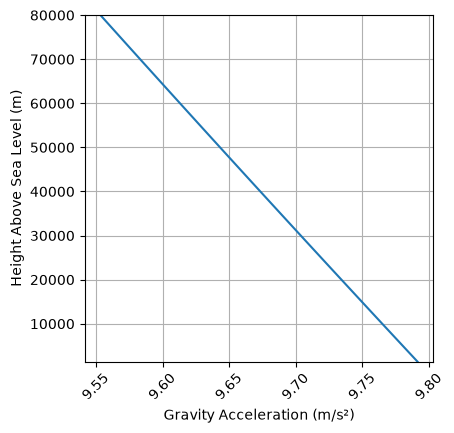



Atmospheric Model Plots


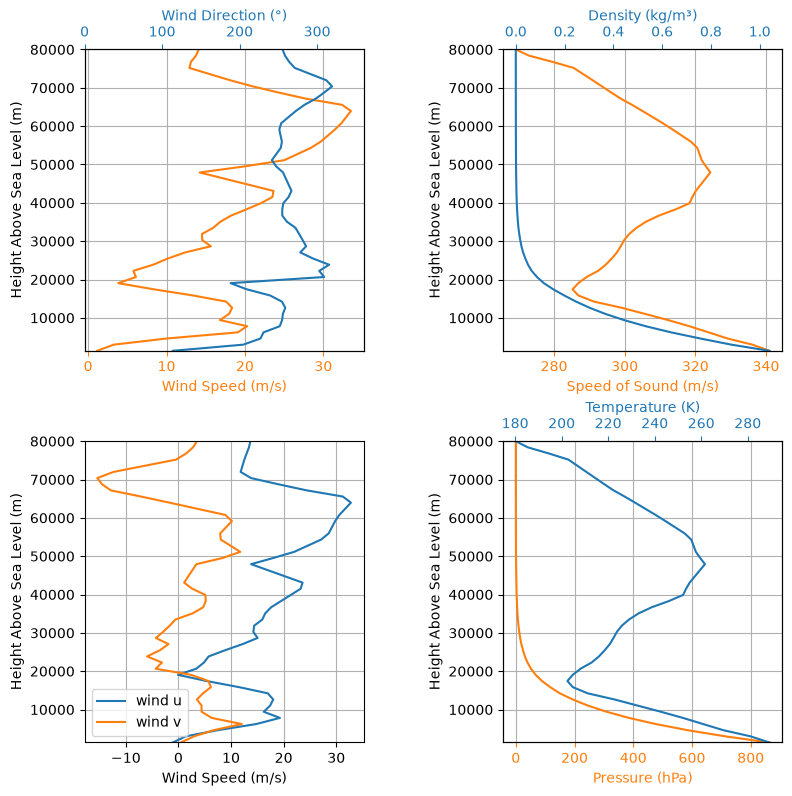

In [2]:
env = Environment(latitude=32.990254, longitude=-106.974998, elevation=1400)
tomorrow = datetime.date.today() + datetime.timedelta(days=1)
env.set_date((tomorrow.year, tomorrow.month, tomorrow.day, 12)) # Hour given in UTC time
env.set_atmospheric_model(type="Forecast", file="GFS")
env.all_info()

In [3]:
calisto = Rocket(
	radius=127 / 2000,
	mass=14.426,
	inertia=(6.321, 6.321, 0.034),
	power_off_drag=ROCKETPY_PATH + "/data/rockets/calisto/powerOffDragCurve.csv",
	power_on_drag=ROCKETPY_PATH + "/data/rockets/calisto/powerOnDragCurve.csv",
	center_of_mass_without_motor=0,
	coordinate_system_orientation="tail_to_nose",
)

In [4]:
Pro75M1670 = SolidMotor(
	thrust_source=ROCKETPY_PATH + "/data/motors/cesaroni/Cesaroni_M1670.eng",
	dry_mass=1.815,
	dry_inertia=(0.125, 0.125, 0.002),
	nozzle_radius=33 / 1000,
	grain_number=5,
	grain_density=1815,
	grain_outer_radius=33 / 1000,
	grain_initial_inner_radius=15 / 1000,
	grain_initial_height=120 / 1000,
	grain_separation=5 / 1000,
	grains_center_of_mass_position=0.397,
	center_of_dry_mass_position=0.317,
	nozzle_position=0,
	burn_time=3.9,
	throat_radius=11 / 1000,
	coordinate_system_orientation="nozzle_to_combustion_chamber",
)
calisto.add_motor(Pro75M1670, position=-1.255)

In [5]:
nose_cone = calisto.add_nose(length=0.55829, kind="von karman", position=1.278)

In [6]:
fin_set = calisto.add_trapezoidal_fins(
	n=4,
	root_chord=0.120,
	tip_chord=0.060,
	span=0.110,
	position=-1.04956,
	cant_angle=0.5,
	airfoil=(ROCKETPY_PATH + "/data/airfoils/NACA0012-radians.txt","radians"),
)

In [7]:
tail = calisto.add_tail(top_radius=0.0635, bottom_radius=0.0435, length=0.060, position=-1.194656)

In [8]:
calisto.parachutes.clear()
main = calisto.add_parachute(
	name="main",
	cd_s=10.0,
	trigger=800,      # ejection altitude in meters
	sampling_rate=105,
	lag=1,
	noise=(0, 8.3, 0.5),
)
drogue = calisto.add_parachute(
	name="drogue",
	cd_s=1.0,
	trigger="apogee",  # ejection at apogee
	sampling_rate=105,
	lag=1,
	noise=(0, 8.3, 0.5),
)

In [17]:
calisto.warn_if_unstable()
test_flight = Flight(rocket=calisto, environment=env, rail_length=5.2, inclination=85, heading=0)


Inertia Details

Rocket Mass: 14.426 kg (without motor)
Rocket Dry Mass: 16.241 kg (with unloaded motor)
Rocket Loaded Mass: 19.197 kg
Rocket Structural Mass Ratio: 0.846
Rocket Inertia (with unloaded motor) 11: 7.864 kg*m2
Rocket Inertia (with unloaded motor) 22: 7.864 kg*m2
Rocket Inertia (with unloaded motor) 33: 0.036 kg*m2
Rocket Inertia (with unloaded motor) 12: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 13: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 23: 0.000 kg*m2

Geometrical Parameters

Rocket Maximum Radius: 0.0635 m
Rocket Frontal Area: 0.012668 m2

Rocket Distances
Rocket Center of Dry Mass - Center of Mass without Motor: 0.105 m
Rocket Center of Dry Mass - Nozzle Exit: 1.150 m
Rocket Center of Dry Mass - Center of Propellant Mass: 0.753 m
Rocket Center of Mass - Rocket Loaded Center of Mass: 0.116 m


Aerodynamics Lift Coefficient Derivatives

Nose Cone Lift Coefficient Derivative: 2.000/rad
Fins Lift Coefficient Derivative: 6.280/rad
Tail Lift Coefficient De

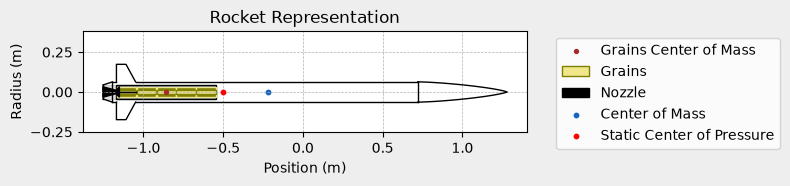


Mass Plots
----------------------------------------


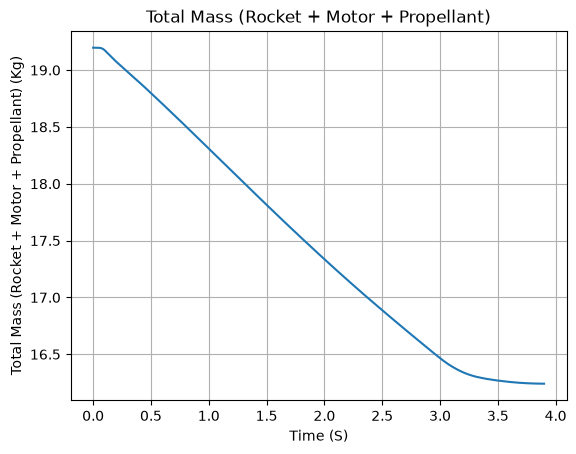

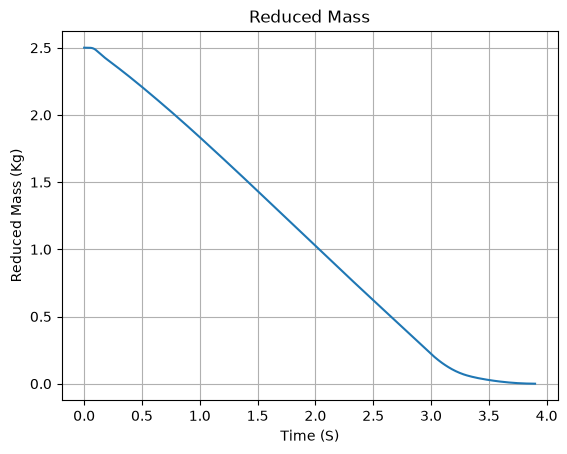


Aerodynamics Plots
----------------------------------------
Drag Plots
--------------------


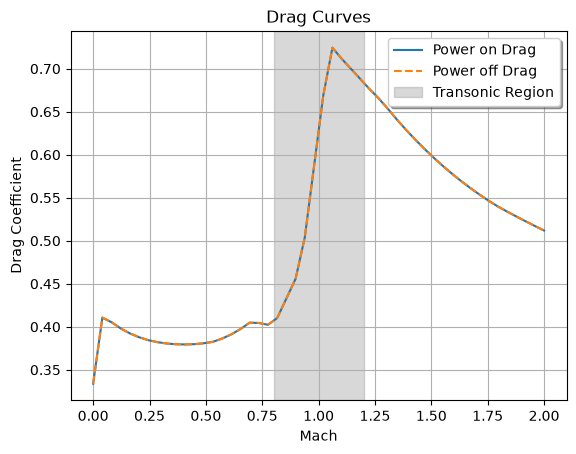


Stability Plots
--------------------


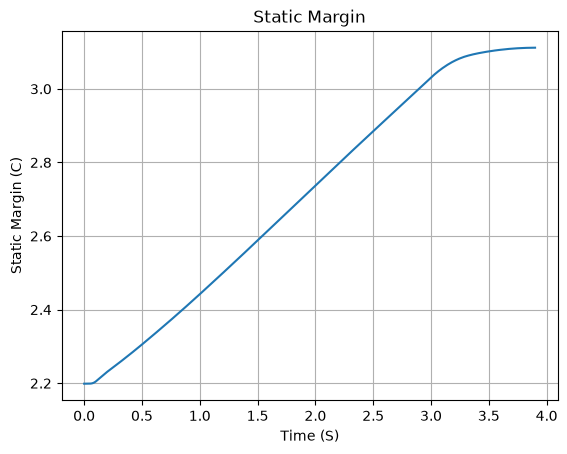

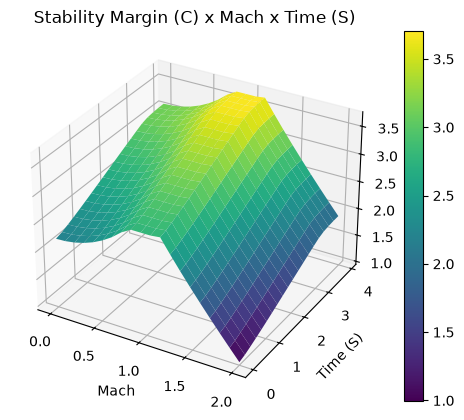


Thrust-to-Weight Plot
----------------------------------------


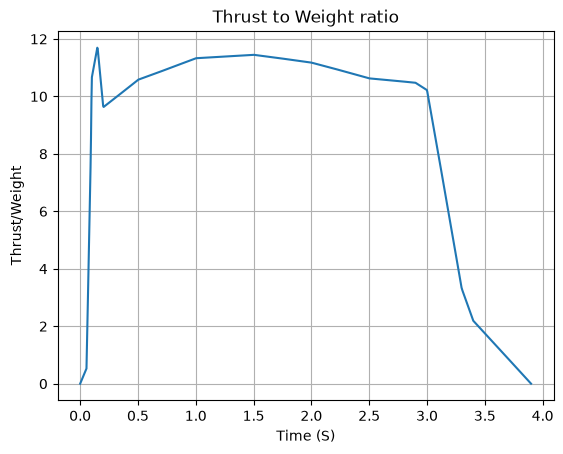

In [13]:
calisto.all_info()


Initial Conditions

Initial time: 0.000 s
Position - x: 0.00 m | y: 0.00 m | z: 1471.47 m
Velocity - Vx: 0.00 m/s | Vy: 0.00 m/s | Vz: 0.00 m/s
Attitude (quaternions) - e0: 0.999 | e1: -0.044 | e2: 0.000 | e3: 0.000
Euler Angles - Spin φ : 0.00° | Nutation θ: -5.00° | Precession ψ: 0.00°
Angular Velocity - ω1: 0.00 rad/s | ω2: 0.00 rad/s | ω3: 0.00 rad/s
Initial Stability Margin: 2.199 c


Surface Wind Conditions

Frontal Surface Wind Speed: 0.50 m/s
Lateral Surface Wind Speed: 1.08 m/s


Launch Rail

Launch Rail Length: 5.2 m
Launch Rail Inclination: 85.00°
Launch Rail Heading: 0.00°


Rail Departure State

Rail Departure Time: 0.415 s
Rail Departure Velocity: 30.474 m/s
Rail Departure Stability Margin: 2.290 c
Rail Departure Angle of Attack: 2.246°
Rail Departure Thrust-Weight Ratio: 10.303
Rail Departure Reynolds Number: 2.227e+05


Burn out State

Burn out time: 3.900 s
Altitude at burn out: 2130.246 m (ASL) | 658.780 m (AGL)
Rocket speed at burn out: 280.648 m/s
Freestream veloci

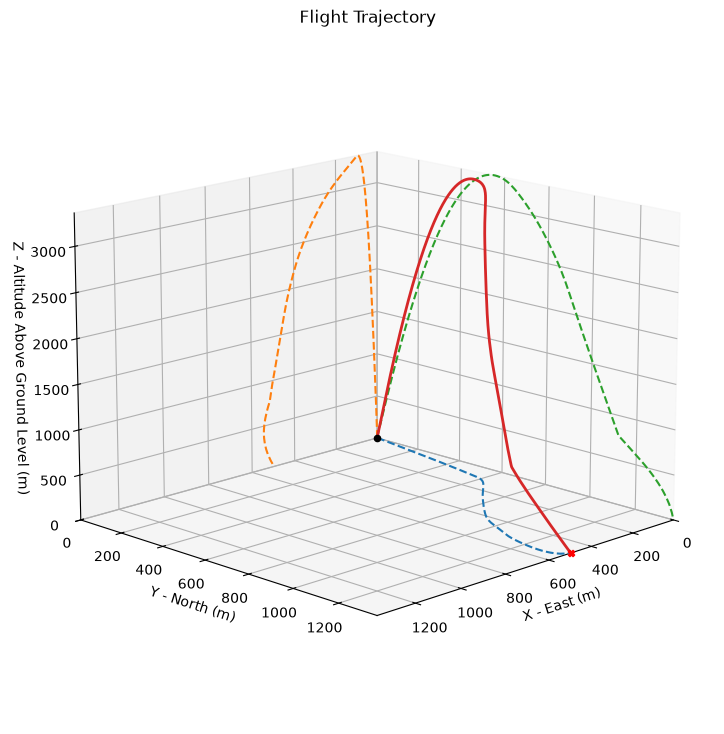



Trajectory Kinematic Plots



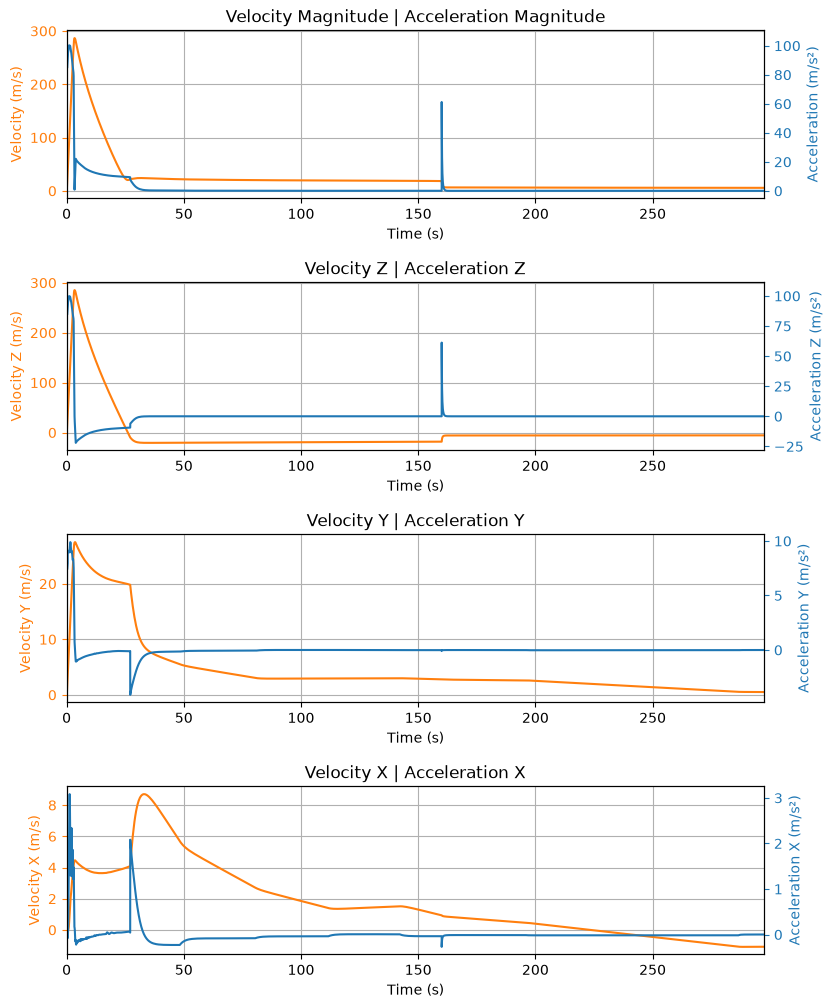



Angular Position Plots



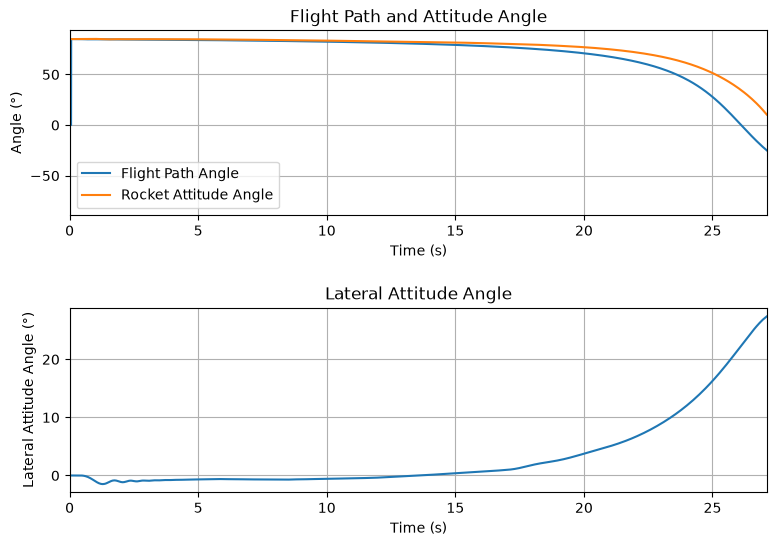



Path, Attitude and Lateral Attitude Angle Plots



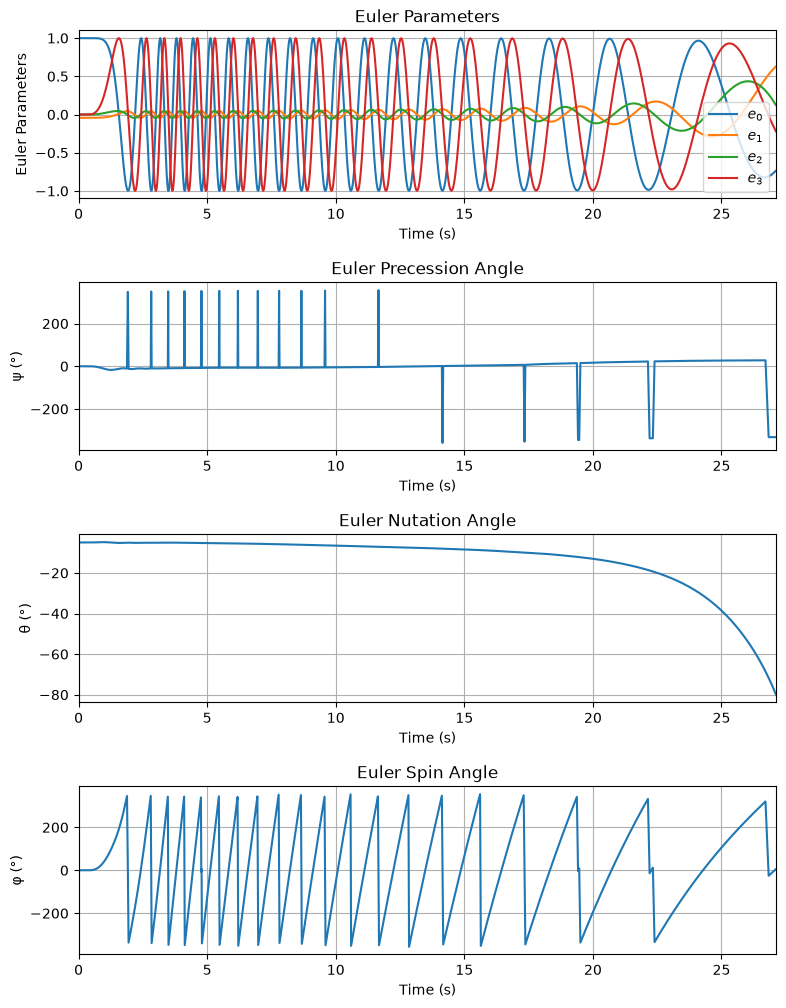



Trajectory Angular Velocity and Acceleration Plots



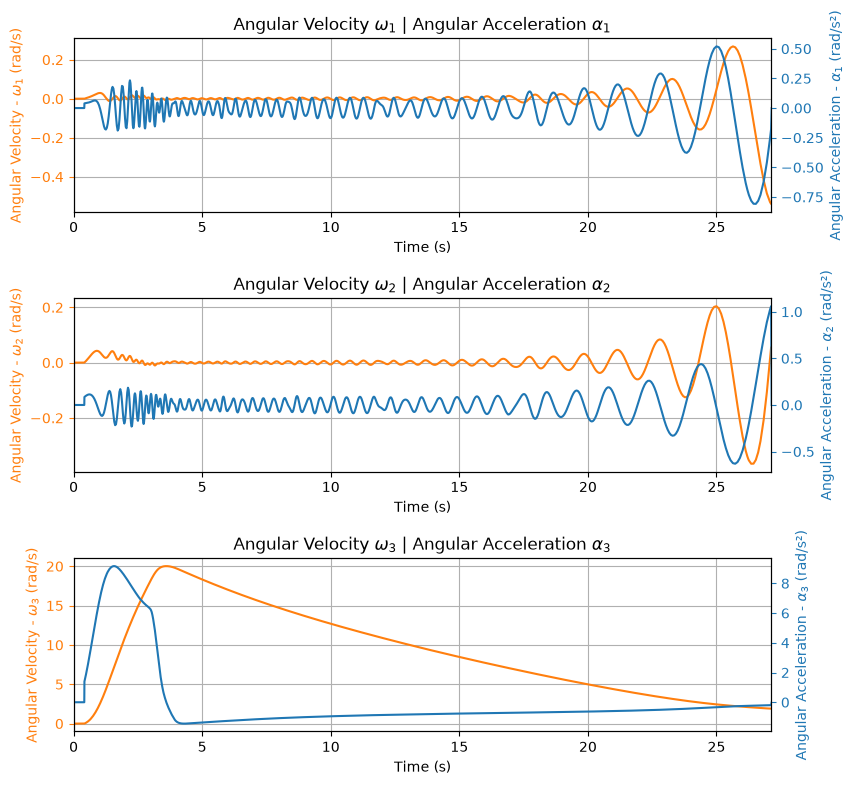



Aerodynamic Forces Plots



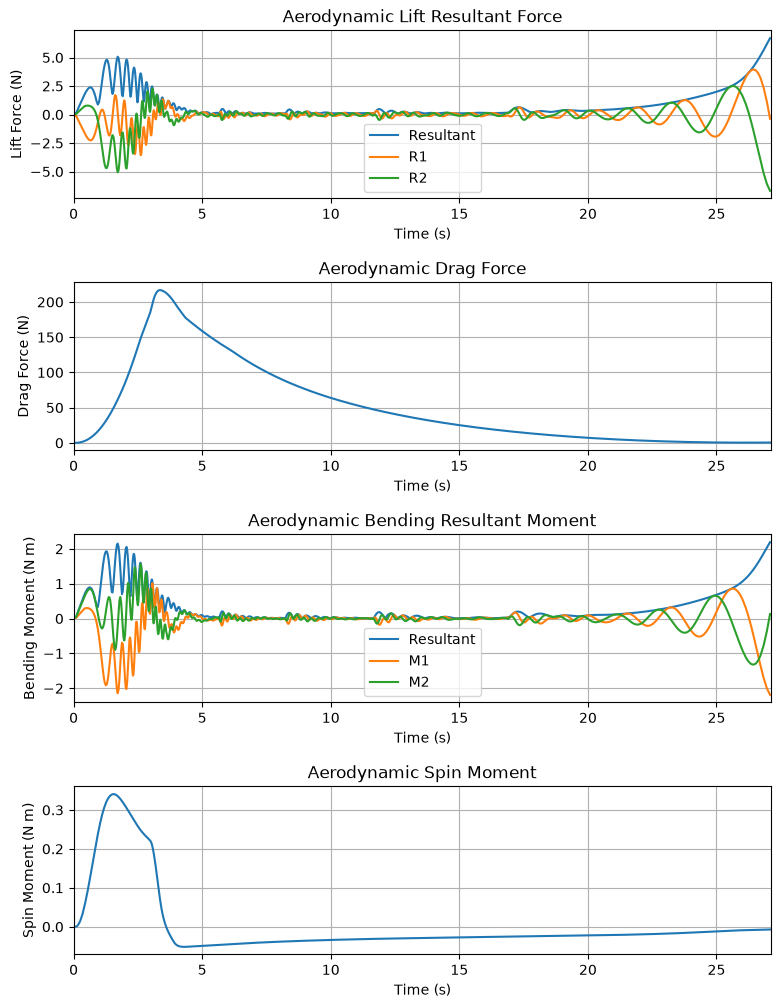

No rail buttons were defined. Skipping rail button bending moment plots.
No rail buttons were defined. Skipping rail button plots.




Rail Buttons Bending Moments Plots



Rail Buttons Forces Plots



Trajectory Energy Plots



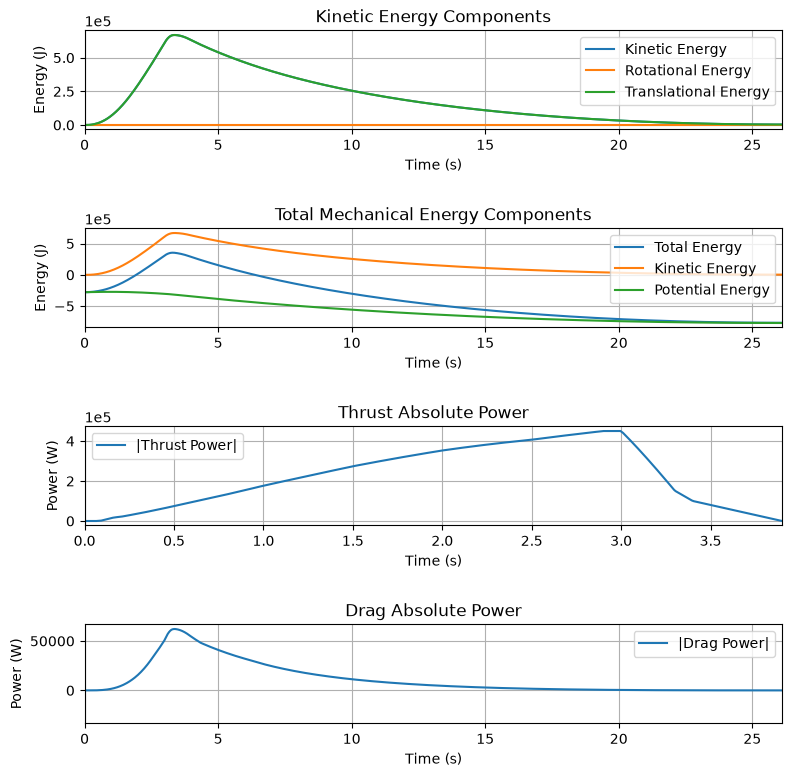



Trajectory Fluid Mechanics Plots



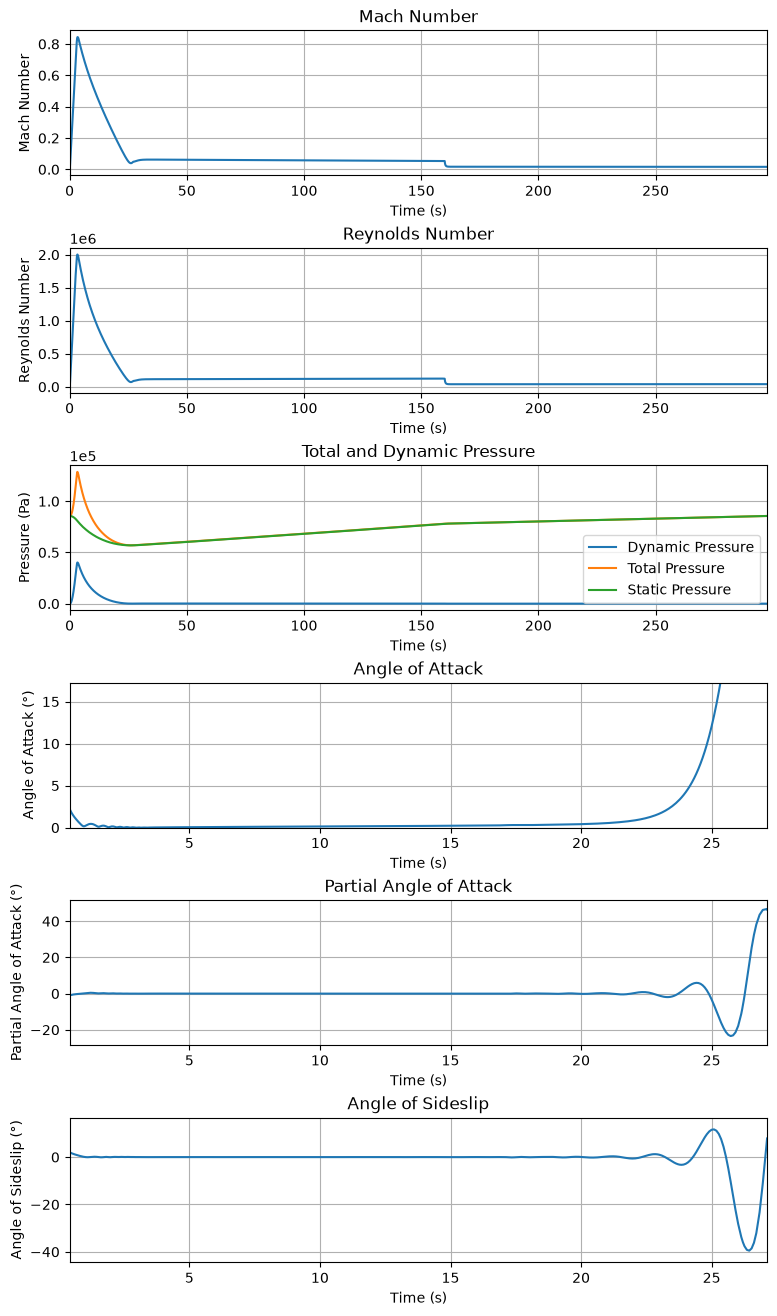



Trajectory Stability and Control Plots



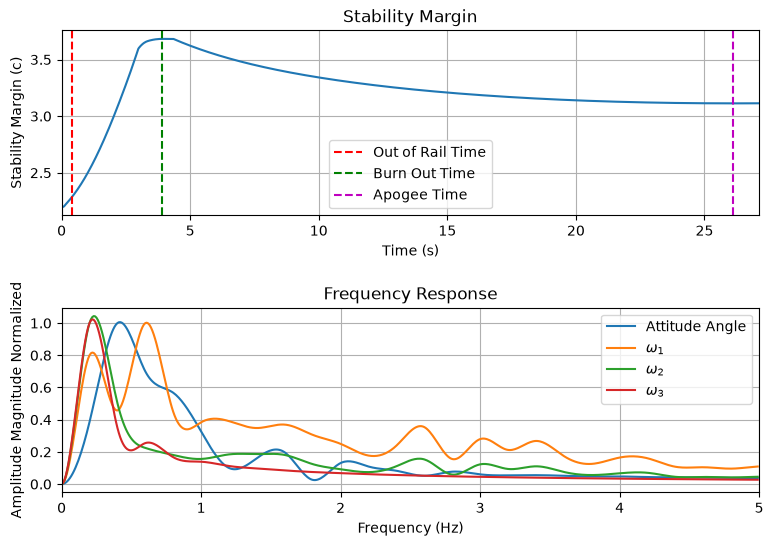



Rocket and Parachute Pressure Plots



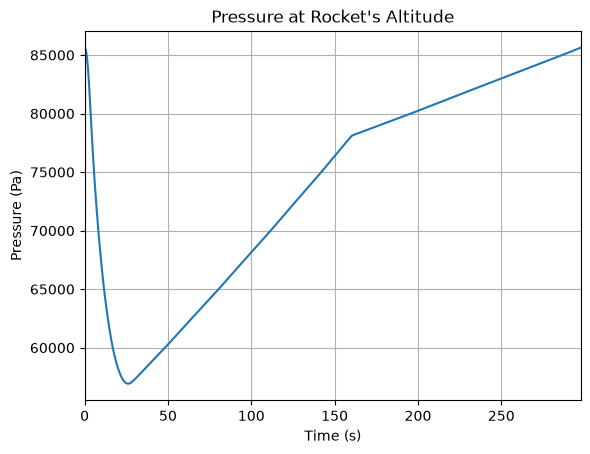

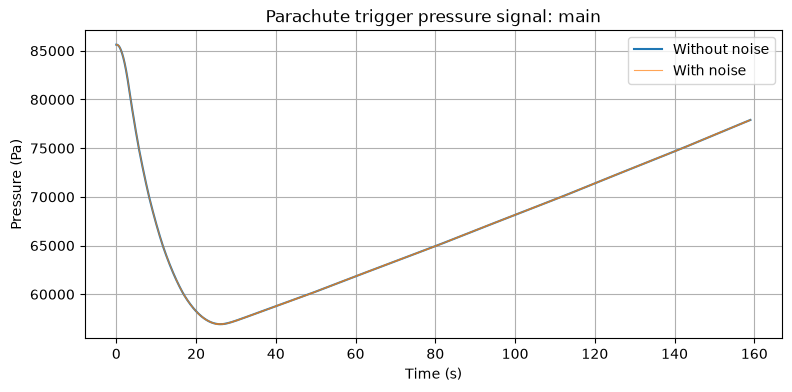

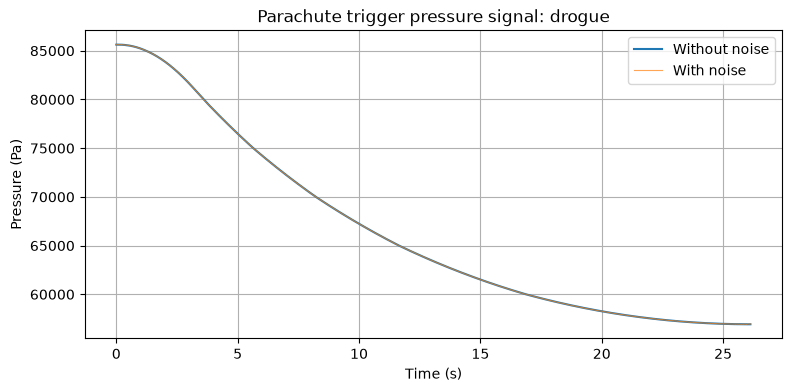

In [11]:
test_flight.all_info()

In [ ]:
EXPORT_FLIGHT = False
if EXPORT_FLIGHT:
    exporter = FlightDataExporter(test_flight)
    exporter.export_kml(file_name="thing.kml", extrude=True, altitude_mode="relative_to_ground")

test_flight.plots.animate_trajectory(
    start=0,                        # start time in seconds (default: 0)
    stop=test_flight.t_final,       # end time in seconds (default: t_final)
    time_step=0.05,                 # seconds per frame (default: 0.1)
    playback_speed=2.0,             # twice real-time playback (default: 1)
    background_color="#A8CBE0",   # optional launch-background override
    color_by="dynamic_pressure",    # speed, Mach, q, acceleration or altitude
    show_kinematic_plots=True,      # altitude, speed and acceleration
    camera_mode="static",           # static, follow, ground or body
    trajectory_line_width=8,        # flown-path width (default: 4)
    show_subrocket_point=True,      # ground projection (default: True)
    force_external = True,
)
# Big fix to make plotter work is to change flight_plots.py by adding a line before line 1204 (plotter.add_timer_event) and insert plotter.iren.initialize().
# flight_plots.py is at path [pathToEnvironment]/Lib/site-packages/rocketpy/plots/flight_plots.py

c:\Users\giova\miniconda3\envs\rocketpy\Lib\site-packages\rocketpy\plots\flight_plots.py:1225: UserWarning: Not within a jupyter notebook environment.
Ignoring ``jupyter_backend``.
  plotter.show(**show_kwargs)
c:\Users\giova\miniconda3\envs\rocketpy\Lib\site-packages\rocketpy\plots\flight_plots.py:1225: UserWarning: `auto_close` ignored: by clicking the exit button, you have destroyed the render window and we have to close it out.
  plotter.show(**show_kwargs)
